# 03 · Fases B y C: H1 en toda la validación, diagnósticos y ablaciones

Todo se evalúa sobre los **chips evaluables de `valid`** (no solo los 9 del E1), con embeddings cacheados. Cada chip se codifica una vez y todas las variantes de prompts y de selección usan el mismo embedding, así que las comparaciones son pareadas.

Lo que se ejecuta corresponde, uno a uno, al protocolo pre-registrado (`docs/protocolo_preregistrado.md`):

* **H1-ext**: SAM v2 frente a Otsu en toda la validación, con IC 95 %.
* **D1 y D2** (oráculos, solo diagnóstico): prompts tomados de la etiqueta y mejor candidata según la etiqueta.
* **D3**: calibración del IoU predicho por el propio SAM.
* **A1 a A4**: ablaciones de la cantidad de prompts, de la regla de selección, del prompt denso y de la composición de bandas.
* **P**: sonda lineal por bloque, para ver en qué capa el agua es linealmente separable.

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from inf659sam import config, data, stats
from inf659sam.cache import encode_and_cache, load_probe_tokens, save_json
from inf659sam.experiments import METHOD_INFO, evaluate_chip, rows_for
from inf659sam.sam_utils import SamWrapper

config.setup_runtime(seed=0)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9})
parts = json.loads((config.RESULTS_DIR / "particiones_usadas.json").read_text(encoding="utf-8"))
VALID, TRAIN = parts["valid"], parts["train"]
sam = SamWrapper()
# Si la cache no existe, se calcula ahora (unos 7 s por chip en CPU con 4 hilos)
encode_and_cache(sam, VALID, rep="vh3", probe=True)
encode_and_cache(sam, VALID, rep="vv_vh_d", probe=False)
print(len(VALID), "chips de valid evaluables")

Entorno: {'seed': 0, 'torch_threads': 8}


Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

Loading weights:  21%|██        | 66/314 [00:00<00:00, 635.17it/s]

Loading weights: 100%|██████████| 314/314 [00:00<00:00, 1590.95it/s]

86 chips de valid evaluables


## 1. Evaluación de todos los métodos, chip por chip

In [2]:
res, res_a4 = [], []
for i, chip in enumerate(VALID, 1):
    res.append(evaluate_chip(sam, chip, rep="vh3"))
    res_a4.append(evaluate_chip(sam, chip, rep="vv_vh_d", methods=("sam_v2", "sam_single")))
    if i % 20 == 0:
        print(f"  {i}/{len(VALID)}")
regions = [r["_meta"]["region"] for r in res]
save_json({"vh3": res, "vv_vh_d": res_a4}, config.RESULTS_DIR / "valid_resultados_por_chip.json")
print("Prompts verificados en la clase correcta en todos los chips:",
      all(r["_meta"]["prompts_ok"] in (True, None) for r in res),
      "| chips sin prompts positivos:", sum(r["_meta"]["n_pos"] == 0 for r in res))

  20/86


  40/86


  60/86


  80/86


Prompts verificados en la clase correcta en todos los chips: True | chips sin prompts positivos: 0


## 2. Tabla agregada con intervalos de confianza

In [3]:
ORDER = ["all_water", "otsu_raw", "otsu_opened", "sam_v2", "sam_single", "sam_min_area", "sam_otsu_consistent",
         "sam_maskprompt", "sam_p1_0", "sam_p5_5", "sam_p10_10", "oracle_select", "oracle_prompts", "oracle_prompts_single"]
tab, comp = [], {}
base_v2 = rows_for(res, "sam_v2")
base_otsu = rows_for(res, "otsu_opened")
for m in ORDER:
    rows = rows_for(res, m)
    a = stats.aggregate(rows)
    bs_otsu = stats.paired_bootstrap(base_otsu, rows, n_boot=5000)
    bs_otsu_reg = stats.paired_bootstrap(base_otsu, rows, groups=regions, n_boot=5000)
    wil = stats.wilcoxon_paired([r["iou"] for r in base_otsu], [r["iou"] for r in rows])
    comp[m] = {"agregado": a, "vs_otsu_chip": bs_otsu, "vs_otsu_region": bs_otsu_reg, "wilcoxon_vs_otsu": wil,
               "vs_sam_v2_chip": stats.paired_bootstrap(base_v2, rows, n_boot=5000)}
    colapso = np.mean([r["area_frac"] > 0.9 for r in rows])
    tab.append({"método": m, "IoU global": a["global_iou"], "IoU medio": a["mean_chip_iou"],
                "precisión": a["precision"], "sensibilidad": a["recall"],
                "Δ vs Otsu (IC95 chip)": "{:+.3f} [{:+.3f}, {:+.3f}]".format(bs_otsu["global_iou"]["diff_b_menos_a"], *bs_otsu["global_iou"]["ic95"]),
                "Δ vs Otsu (IC95 región)": "[{:+.3f}, {:+.3f}]".format(*bs_otsu_reg["global_iou"]["ic95"]),
                "chips mejor que Otsu": f"{wil['b_mejor']}/{wil['n']}", "Wilcoxon p": wil.get("p_valor"),
                "% chips colapsados (>90 % agua)": 100 * colapso})
rows4 = rows_for(res_a4, "sam_v2")
a4 = stats.aggregate(rows4)
bs_a4 = stats.paired_bootstrap(base_v2, rows4, n_boot=5000)
rows4s = rows_for(res_a4, "sam_single")
a4s = stats.aggregate(rows4s)
bs_a4s = stats.paired_bootstrap(rows_for(res, "sam_single"), rows4s, n_boot=5000)
comp["A4_vv_vh_d_sam_v2"] = {"agregado": a4, "vs_sam_v2_vh3": bs_a4}
comp["A4_vv_vh_d_sam_single"] = {"agregado": a4s, "vs_sam_single_vh3": bs_a4s}
df_tab = pd.DataFrame(tab).set_index("método")
save_json(comp, config.RESULTS_DIR / "valid_comparaciones.json")
print(f"A4 [VV,VH,VV-VH] SAM v2: IoU global {a4['global_iou']:.4f} | Δ vs VH×3 {bs_a4['global_iou']['diff_b_menos_a']:+.4f} "
      f"IC95 [{bs_a4['global_iou']['ic95'][0]:+.4f}, {bs_a4['global_iou']['ic95'][1]:+.4f}]")
print(f"A4 [VV,VH,VV-VH] SAM una máscara: IoU global {a4s['global_iou']:.4f} | Δ vs VH×3 {bs_a4s['global_iou']['diff_b_menos_a']:+.4f} "
      f"IC95 [{bs_a4s['global_iou']['ic95'][0]:+.4f}, {bs_a4s['global_iou']['ic95'][1]:+.4f}]")
df_tab.round(4)

A4 [VV,VH,VV-VH] SAM v2: IoU global 0.1124 | Δ vs VH×3 -0.0022 IC95 [-0.0065, +0.0022]
A4 [VV,VH,VV-VH] SAM una máscara: IoU global 0.1238 | Δ vs VH×3 -0.0147 IC95 [-0.0302, -0.0014]


,IoU global,IoU medio,precisión,sensibilidad,Δ vs Otsu (IC95 chip),Δ vs Otsu (IC95 región),chips mejor que Otsu,Wilcoxon p,% chips colapsados (>90 % agua)
método,,,,,,,,,
all_water,0.1100,0.1140,0.1101,0.9971,"-0.146 [-0.188, -0.106]","[-0.198, -0.096]",5/86,0.0000,98.8372
otsu_raw,0.2199,0.2367,0.2365,0.7582,"-0.036 [-0.044, -0.028]","[-0.045, -0.026]",10/86,0.0000,0.0000
otsu_opened,0.2556,0.2525,0.2822,0.7308,"+0.000 [+0.000, +0.000]","[+0.000, +0.000]",0/86,NaN,0.0000
sam_v2,0.1146,0.1458,0.1181,0.7932,"-0.141 [-0.181, -0.103]","[-0.197, -0.091]",8/86,0.0000,47.6744
sam_single,0.1385,0.1667,0.1498,0.6479,"-0.117 [-0.153, -0.083]","[-0.156, -0.078]",13/86,0.0000,10.4651
sam_min_area,0.2056,0.1754,0.2645,0.4798,"-0.050 [-0.091, -0.010]","[-0.090, -0.016]",19/86,0.0002,0.0000
sam_otsu_consistent,0.1274,0.1807,0.1382,0.6189,"-0.128 [-0.159, -0.095]","[-0.170, -0.085]",13/86,0.0000,23.2558
sam_maskprompt,0.2807,0.2703,0.3113,0.7407,"+0.025 [+0.015, +0.037]","[+0.014, +0.041]",55/86,0.0000,0.0000
sam_p1_0,0.1690,0.2137,0.1752,0.8286,"-0.087 [-0.128, -0.042]","[-0.127, -0.043]",16/85,0.0006,43.0233


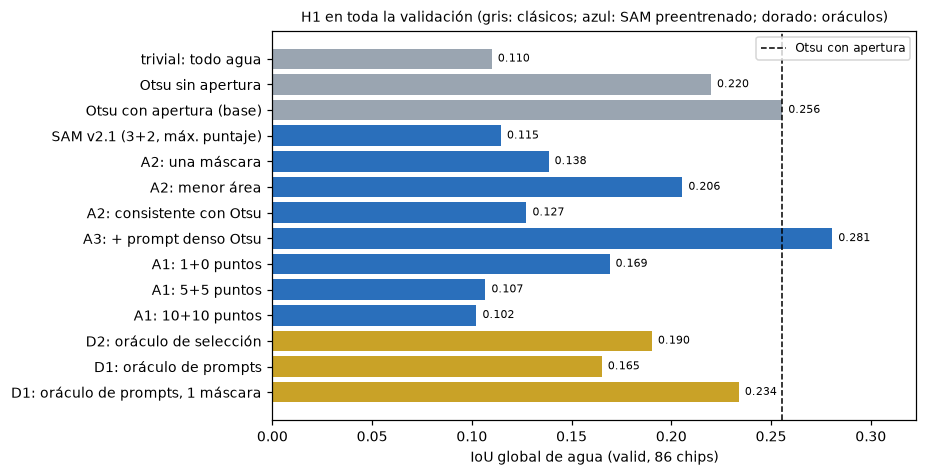

In [4]:
ETQ = {"all_water": "trivial: todo agua", "otsu_raw": "Otsu sin apertura", "otsu_opened": "Otsu con apertura (base)",
       "sam_v2": "SAM v2.1 (3+2, máx. puntaje)", "sam_single": "A2: una máscara", "sam_min_area": "A2: menor área",
       "sam_otsu_consistent": "A2: consistente con Otsu", "sam_maskprompt": "A3: + prompt denso Otsu",
       "sam_p1_0": "A1: 1+0 puntos", "sam_p5_5": "A1: 5+5 puntos", "sam_p10_10": "A1: 10+10 puntos",
       "oracle_select": "D2: oráculo de selección", "oracle_prompts": "D1: oráculo de prompts",
       "oracle_prompts_single": "D1: oráculo de prompts, 1 máscara"}
fig, ax = plt.subplots(figsize=(8.5, 4.4))
show = list(ORDER)
vals = [comp[m]["agregado"]["global_iou"] for m in show]
cols = ["#9aa5b1" if (m.startswith("otsu") or m == "all_water") else ("#c9a227" if m.startswith("oracle") else "#2a6fbb") for m in show]
ax.barh([ETQ[m] for m in show], vals, color=cols)
for i, v_ in enumerate(vals):
    ax.text(v_ + 0.003, i, f"{v_:.3f}", va="center", fontsize=7)
ax.axvline(comp["otsu_opened"]["agregado"]["global_iou"], color="k", ls="--", lw=1, label="Otsu con apertura")
ax.invert_yaxis()
ax.set_xlim(0, max(vals) * 1.15)
ax.set_xlabel("IoU global de agua (valid, %d chips)" % len(VALID))
ax.set_title("H1 en toda la validación (gris: clásicos; azul: SAM preentrenado; dorado: oráculos)", fontsize=9)
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.savefig(config.FIG_DIR / "valid_metodos_iou_global.png")
plt.show()

## 3. D3: ¿el IoU predicho por SAM sirve como señal de calidad en SAR?

Todas las candidatas: Spearman ρ = -0.052 (p = 0.4), n = 258
Candidata elegida: IoU predicho medio 0.955 frente a IoU real medio 0.146; ρ = -0.262


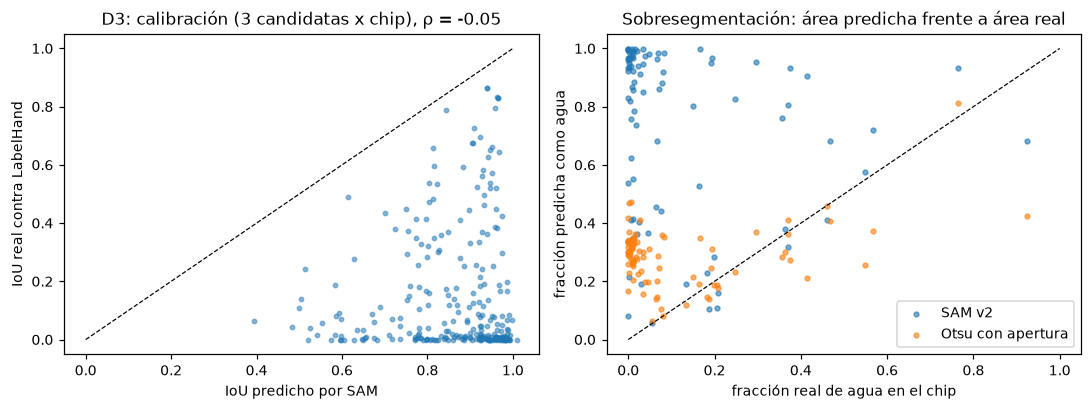

In [5]:
sc, io = [], []
for r in res:
    v = r["sam_v2"]
    if v.get("cand_scores"):
        for s, i_ in zip(v["cand_scores"], v["cand_ious"]):
            if i_ is not None:
                sc.append(s)
                io.append(i_)
rho, p = spearmanr(sc, io)
sel_s = [r["sam_v2"]["score"] for r in res if r["sam_v2"].get("score") is not None]
sel_i = [r["sam_v2"]["iou"] for r in res if r["sam_v2"].get("score") is not None]
rho_sel, p_sel = spearmanr(sel_s, sel_i)
print(f"Todas las candidatas: Spearman ρ = {rho:.3f} (p = {p:.2g}), n = {len(sc)}")
print(f"Candidata elegida: IoU predicho medio {np.mean(sel_s):.3f} frente a IoU real medio {np.mean(sel_i):.3f}; ρ = {rho_sel:.3f}")
comp["D3_calibracion"] = {"spearman_todas": rho, "p_todas": p, "n": len(sc), "spearman_elegida": rho_sel,
                          "score_medio_elegida": float(np.mean(sel_s)), "iou_real_medio_elegida": float(np.mean(sel_i))}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].scatter(sc, io, s=8, alpha=0.5)
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].set_xlabel("IoU predicho por SAM")
axes[0].set_ylabel("IoU real contra LabelHand")
axes[0].set_title(f"D3: calibración (3 candidatas x chip), ρ = {rho:.2f}")
wf = [r["_meta"]["water_frac_gt"] for r in res]
af = [r["sam_v2"]["area_frac"] for r in res]
axes[1].scatter(wf, af, s=10, alpha=0.6, label="SAM v2")
axes[1].scatter(wf, [r["otsu_opened"]["area_frac"] for r in res], s=10, alpha=0.6, label="Otsu con apertura")
axes[1].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[1].set_xlabel("fracción real de agua en el chip")
axes[1].set_ylabel("fracción predicha como agua")
axes[1].set_title("Sobresegmentación: área predicha frente a área real")
axes[1].legend()
plt.tight_layout()
plt.savefig(config.FIG_DIR / "valid_calibracion_y_colapso.png")
plt.show()

## 4. Resultados por región

In [6]:
reg_rows = []
for reg in sorted(set(regions)):
    idx = [i for i, g in enumerate(regions) if g == reg]
    row = {"región": reg, "chips": len(idx)}
    for m in ("otsu_opened", "sam_v2", "sam_single", "oracle_prompts"):
        row[m] = stats.aggregate([res[i][m] for i in idx])["global_iou"]
    reg_rows.append(row)
df_reg = pd.DataFrame(reg_rows).set_index("región")
comp["por_region"] = reg_rows
df_reg.round(3)

,chips,otsu_opened,sam_v2,sam_single,oracle_prompts
región,,,,,
Ghana,8,0.215,0.156,0.188,0.236
India,14,0.342,0.169,0.222,0.215
Mekong,6,0.542,0.126,0.319,0.191
Nigeria,4,0.320,0.263,0.302,0.335
Pakistan,6,0.202,0.106,0.053,0.146
Paraguay,14,0.264,0.099,0.120,0.129
Somalia,5,0.045,0.045,0.044,0.066
Spain,6,0.501,0.186,0.230,0.213
Sri-Lanka,9,0.216,0.087,0.106,0.106


## 5. P: ¿en qué bloque el agua es linealmente separable?

Una regresión logística se entrena con tokens de `train` y se evalúa con tokens de `valid`, en chips distintos. Como control se usa el valor medio de VV y VH en dB del parche de 8×8 píxeles de cada token: es la misma información que usa Otsu.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

encode_and_cache(sam, TRAIN, rep="vh3", probe=True)
tok_tr = load_probe_tokens(TRAIN)
tok_va = load_probe_tokens(VALID)


def backscatter_tokens(chips):
    X, y = [], []
    for chip in chips:
        z = np.load(config.CACHE_DIR / "emb_vh3" / f"{chip}.npz")
        if len(z["tok_y"]) == 0:
            continue
        dd = data.load_chip(chip)
        for (i, j), lab in zip(z["tok_idx"], z["tok_y"]):
            blk = np.s_[8 * i:8 * i + 8, 8 * j:8 * j + 8]
            X.append([np.nanmean(dd["vv"][blk]), np.nanmean(dd["vh"][blk])])
            y.append(lab)
    X = np.nan_to_num(np.array(X, dtype=np.float32), nan=-25.0)
    return X, np.array(y)


probe_rows = []
Xb_tr, yb_tr = backscatter_tokens(TRAIN)
Xb_va, yb_va = backscatter_tokens(VALID)
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
clf.fit(Xb_tr, yb_tr)
pb = clf.predict_proba(Xb_va)[:, 1]
probe_rows.append({"representación": "VV y VH en dB (control, 2 rasgos)", "AUC": roc_auc_score(yb_va, pb),
                   "exactitud balanceada": balanced_accuracy_score(yb_va, pb > 0.5), "n_train": len(yb_tr), "n_valid": len(yb_va)})
for key in [f"tok_l{l}" for l in (0, 2, 5, 8, 11)] + ["tok_neck"]:
    Xtr, ytr, _ = tok_tr[key]
    Xva, yva, _ = tok_va[key]
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.1))
    clf.fit(Xtr, ytr)
    pv = clf.predict_proba(Xva)[:, 1]
    name = "cuello (256, entrada del decodificador)" if key == "tok_neck" else f"bloque {key[5:]} (768)"
    probe_rows.append({"representación": name, "AUC": roc_auc_score(yva, pv),
                       "exactitud balanceada": balanced_accuracy_score(yva, pv > 0.5), "n_train": len(ytr), "n_valid": len(yva)})
df_probe = pd.DataFrame(probe_rows)
comp["P_sonda_por_capa"] = probe_rows
save_json(comp, config.RESULTS_DIR / "valid_comparaciones.json")
df_probe.round(4)

,representación,AUC,exactitud balanceada,n_train,n_valid
0,"VV y VH en dB (control, 2 rasgos)",0.9065,0.8210,13589,4766
1,bloque 0 (768),0.9105,0.8287,13589,4766
2,bloque 2 (768),0.9328,0.8624,13589,4766
3,bloque 5 (768),0.9341,0.8558,13589,4766
4,bloque 8 (768),0.9335,0.8561,13589,4766
5,bloque 11 (768),0.9308,0.8526,13589,4766
6,"cuello (256, entrada del decodificador)",0.9189,0.8402,13589,4766


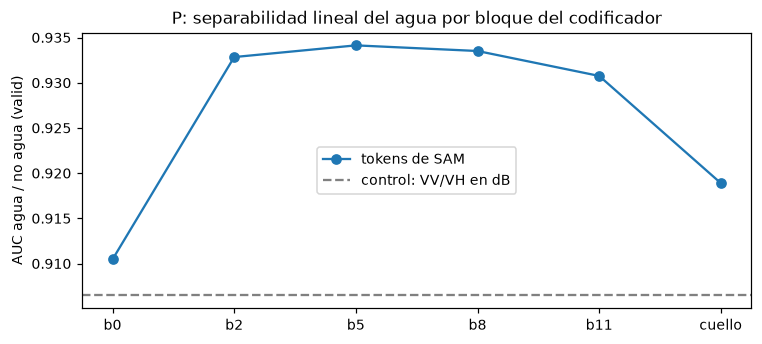

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(range(len(df_probe) - 1), df_probe["AUC"][1:], "o-", label="tokens de SAM")
ax.axhline(df_probe["AUC"][0], color="gray", ls="--", label="control: VV/VH en dB")
ax.set_xticks(range(len(df_probe) - 1))
ax.set_xticklabels(["b0", "b2", "b5", "b8", "b11", "cuello"])
ax.set_ylabel("AUC agua / no agua (valid)")
ax.set_title("P: separabilidad lineal del agua por bloque del codificador")
ax.legend()
plt.tight_layout()
plt.savefig(config.FIG_DIR / "valid_sonda_por_capa.png")
plt.show()